# Predicting 12-month hospitalization after diabetes medication initiation
## Notebook 2: Logistic regression versus XGBoost

This notebook compares four controlled pipelines on the same synthetic cohort and data splits:

1. Minimally processed logistic regression
2. Prepared logistic regression
3. Raw-feature tree-based XGBoost
4. Prepared-feature XGBoost as a preprocessing control

> All records are synthetic. Model performance is for teaching purposes and must not be interpreted as clinical validation.

## tl;dr

- Three existing utilization variables are re-expressed with heavier upper tails to make the preprocessing contrast easier to see.
- The minimally processed logistic model receives the highly skewed values directly.
- The prepared logistic model applies `log1p` and removes the redundant total-visit field, while XGBoost can learn threshold splits on the raw scales.
- Rerun the notebook to populate performance metrics for the adjusted teaching data.
- These are synthetic teaching results, not evidence of clinical validity or universal model superiority.

## Goal

The comparison is designed to separate two questions:

- What does preprocessing contribute to regularized logistic regression?
- Can a tree-based XGBoost model use unscaled, untransformed numeric features and native missing values?

Every model uses the same training, validation, and test patients. The validation set selects one probability threshold per model. The test set is used only once for final evaluation.

## Setup

In [89]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from IPython.display import display

from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import MissingIndicator, SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, MinMaxScaler, OneHotEncoder

from xgboost import XGBClassifier

RANDOM_SEED = 20261013
TARGET = "hospitalized_12m"
BASELINE_DAYS = 365

sns.set_theme(style="whitegrid", context="notebook")
MODEL_COLORS = {
    "Logistic: minimal": "#D4A72C",
    "Logistic: prepared": "#2563EB",
    "XGBoost: raw": "#E76F51",
    "XGBoost: prepared": "#6B7D3A",
}
plt.rcParams.update({
    "figure.figsize": (9, 5),
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "legend.frameon": False,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

## Step 1: Rebuild the leakage-safe analysis table

In [90]:
patients = pd.read_csv("../data/patients.csv", parse_dates=["index_date"])
labs = pd.read_csv("../data/labs.csv", parse_dates=["lab_date"])

labs_with_index = labs.merge(
    patients[["patient_id", "index_date"]],
    on="patient_id",
    how="left",
    validate="many_to_one",
)
baseline_start = labs_with_index["index_date"] - pd.Timedelta(days=BASELINE_DAYS)
baseline_mask = (
    (labs_with_index["lab_date"] >= baseline_start)
    & (labs_with_index["lab_date"] < labs_with_index["index_date"])
)
baseline_labs = labs_with_index.loc[baseline_mask, ["patient_id", "lab_name", "lab_value"]]
assert not baseline_labs.duplicated(["patient_id", "lab_name"]).any()

baseline_labs_wide = (
    baseline_labs.pivot(index="patient_id", columns="lab_name", values="lab_value")
    .reset_index()
    .rename_axis(columns=None)
)
model_data = patients.merge(baseline_labs_wide, on="patient_id", how="left", validate="one_to_one")
assert len(model_data) == len(patients)

display(model_data.head(3))
print(f"Modeling cohort: {len(model_data):,} patients")
print(f"Outcome prevalence: {model_data[TARGET].mean():.1%}")

,patient_id,index_date,index_medication_class,age_at_index,sex,race_ethnicity,insurance_type,smoking_status,diabetes_duration_years,bmi_baseline,...,charlson_comorbidity_index,hospitalized_12m,alt,creatinine,egfr,glucose,hba1c,hdl_cholesterol,ldl_cholesterol,triglycerides
0,P000001,2022-02-26,SGLT2 inhibitor,75,Male,Asian,Commercial,Never,4.0,47.0,...,2,0,13.0,0.68,84.0,NaN,8.2,36.0,110.0,93.0
1,P000002,2022-10-11,Insulin,63,Female,Black,Commercial,Former,15.0,NaN,...,1,0,NaN,0.99,90.0,275.0,10.9,67.0,155.0,NaN
2,P000003,2022-08-26,Metformin,79,Male,White,Medicare,Never,10.5,34.6,...,2,0,45.0,0.64,79.0,173.0,8.3,53.0,132.0,65.0


Modeling cohort: 4,000 patients
Outcome prevalence: 22.4%


## Step 2: Create fixed training, validation, and test sets

In [91]:
identifiers = model_data[["patient_id", "index_date"]]
X = model_data.drop(columns=["patient_id", "index_date", TARGET])
y = model_data[TARGET]

X_development, X_test, y_development, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_SEED,
    stratify=y,
)
X_train, X_validation, y_train, y_validation = train_test_split(
    X_development,
    y_development,
    test_size=0.25,
    random_state=RANDOM_SEED,
    stratify=y_development,
)

split_summary = pd.DataFrame({
    "patients": [len(X_train), len(X_validation), len(X_test)],
    "outcome_rate": [y_train.mean(), y_validation.mean(), y_test.mean()],
}, index=["Training", "Validation", "Test"])
display(split_summary.style.format({"patients": "{:,.0f}", "outcome_rate": "{:.1%}"}))

,patients,outcome_rate
Training,"2,400",22.3%
Validation,800,22.4%
Test,800,22.4%


The split occurs before fitting imputation, transformations, scaling, or encoders. Every preprocessing pipeline learns its parameters from the training set only.

## Step 3: Define the minimally processed logistic-regression pipeline

Logistic regression cannot accept missing numeric values or text categories directly. The minimal pipeline therefore uses median imputation and one-hot encoding, but deliberately omits log transformation, scaling, and multicollinearity resolution.

In [92]:
categorical_columns = X.select_dtypes(include=["object", "string", "category"]).columns.tolist()
numeric_columns = [column for column in X.columns if column not in categorical_columns]

minimal_logistic_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", SimpleImputer(strategy="median"), numeric_columns),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore")),
            ]),
            categorical_columns,
        ),
    ],
    verbose_feature_names_out=False,
)

minimal_logistic = Pipeline([
    ("preprocess", minimal_logistic_preprocessor),
    ("model", LogisticRegression(max_iter=3000, C=1.0, solver="lbfgs")),
])

## Step 4: Define the prepared logistic-regression pipeline

The prepared pipeline:

- drops `total_visits_baseline` while retaining its component counts;
- median-imputes continuous variables;
- applies `log1p` to skewed nonnegative variables;
- standardizes continuous variables;
- adds missingness indicators;
- imputes binary indicators without scaling; and
- one-hot encodes categorical variables.

In [93]:
X_prepared = X.drop(columns=["total_visits_baseline"]).copy()
Xp_train = X_train.drop(columns=["total_visits_baseline"]).copy()
Xp_validation = X_validation.drop(columns=["total_visits_baseline"]).copy()
Xp_test = X_test.drop(columns=["total_visits_baseline"]).copy()

binary_columns = [
    "prior_hospitalization_baseline",
    "hypertension_baseline",
    "hyperlipidemia_baseline",
    "chronic_kidney_disease_baseline",
    "cardiovascular_disease_baseline",
    "heart_failure_baseline",
    "diabetes_complication_baseline",
    "depression_baseline",
]
log_numeric_columns = [
    "outpatient_visits_baseline",
    "er_visits_baseline",
    "inpatient_visits_baseline",
    "diabetes_duration_years",
    "medication_count_baseline",
    "charlson_comorbidity_index",
    "creatinine",
    "triglycerides",
    "alt",
]
prepared_categorical_columns = X_prepared.select_dtypes(include=["object", "string", "category"]).columns.tolist()
continuous_columns = [
    column
    for column in X_prepared.columns
    if column not in prepared_categorical_columns + binary_columns + log_numeric_columns
]
columns_with_missing_flags = continuous_columns + log_numeric_columns

prepared_preprocessor = ColumnTransformer(
    transformers=[
        (
            "continuous",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scale", MinMaxScaler()),
            ]),
            continuous_columns,
        ),
        (
            "log_numeric",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                ("scale", MinMaxScaler()),
            ]),
            log_numeric_columns,
        ),
        (
            "missing_flags",
            MissingIndicator(features="missing-only", error_on_new=False),
            columns_with_missing_flags,
        ),
        ("binary", SimpleImputer(strategy="most_frequent"), binary_columns),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore")),
            ]),
            prepared_categorical_columns,
        ),
    ],
    verbose_feature_names_out=True,
)

prepared_logistic = Pipeline([
    ("preprocess", prepared_preprocessor),
    ("model", LogisticRegression(max_iter=1500, C=1.0, solver="lbfgs")),
])

## Step 5: Define raw and prepared XGBoost pipelines

The raw XGBoost pipeline keeps numeric values on their original scales, does not apply log transformations, retains correlated visit fields, and passes numeric `NaN` values to the tree booster. Categories are one-hot encoded so the model comparison does not introduce a separate lesson on native categorical handling.

In [94]:
raw_xgb_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", "passthrough", numeric_columns),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore")),
            ]),
            categorical_columns,
        ),
    ],
    sparse_threshold=1.0,
    verbose_feature_names_out=False,
)

xgb_base_parameters = dict(
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=RANDOM_SEED,
    n_jobs=1,
)

raw_xgboost = Pipeline([
    ("preprocess", raw_xgb_preprocessor),
    ("model", XGBClassifier(**xgb_base_parameters)),
])

prepared_xgboost = Pipeline([
    ("preprocess", clone(prepared_preprocessor)),
    ("model", XGBClassifier(**xgb_base_parameters)),
])

xgb_parameter_distributions = {
    "model__n_estimators": [200, 350, 500, 700],
    "model__learning_rate": [0.02, 0.04, 0.07, 0.10],
    "model__max_depth": [2, 3, 4, 5],
    "model__min_child_weight": [1, 3, 5, 10],
    "model__subsample": [0.70, 0.85, 1.00],
    "model__colsample_bytree": [0.70, 0.85, 1.00],
    "model__gamma": [0.00, 0.10, 0.25],
    "model__reg_alpha": [0.00, 0.10, 0.50],
    "model__reg_lambda": [1.0, 2.0, 5.0],
}

xgb_cross_validation = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_SEED,
)

def build_xgb_search(pipeline):
    return RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=xgb_parameter_distributions,
        n_iter=20,
        scoring="roc_auc",
        cv=xgb_cross_validation,
        refit=True,
        random_state=RANDOM_SEED,
        n_jobs=2,
        return_train_score=False,
    )

raw_xgboost_search = build_xgb_search(raw_xgboost)
prepared_xgboost_search = build_xgb_search(prepared_xgboost)

## Step 6: Train every model on the same training patients

In [95]:
models = {
    "Logistic: minimal": (minimal_logistic, X_train, X_validation, X_test),
    "Logistic: prepared": (prepared_logistic, Xp_train, Xp_validation, Xp_test),
    "XGBoost: raw": (raw_xgboost_search, X_train, X_validation, X_test),
    "XGBoost: prepared": (prepared_xgboost_search, Xp_train, Xp_validation, Xp_test),
}

fitted_models = {}
xgb_tuning_results = {}

for model_name, (model, train_features, validation_features, test_features) in models.items():
    with warnings.catch_warnings():
        # Keep other warnings visible; silence only logistic lbfgs convergence warnings.
        warnings.filterwarnings("ignore", message="lbfgs failed to converge.*", category=ConvergenceWarning)
        model.fit(train_features, y_train)
    if isinstance(model, RandomizedSearchCV):
        fitted_models[model_name] = model.best_estimator_
        xgb_tuning_results[model_name] = {
            "best_cross_validated_AUROC": model.best_score_,
            **model.best_params_,
        }
    else:
        fitted_models[model_name] = model

display(pd.DataFrame(xgb_tuning_results).T)

,best_cross_validated_AUROC,model__subsample,model__reg_lambda,model__reg_alpha,model__n_estimators,model__min_child_weight,model__max_depth,model__learning_rate,model__gamma,model__colsample_bytree
XGBoost: raw,0.817487,0.7,5.0,0.0,200.0,1.0,2.0,0.07,0.10,0.85
XGBoost: prepared,0.815708,0.7,2.0,0.0,700.0,3.0,2.0,0.02,0.25,0.70


## Step 7: Select probability thresholds on validation data

In [96]:
def select_youden_threshold(y_true, probabilities):
    false_positive_rate, true_positive_rate, thresholds = roc_curve(y_true, probabilities)
    finite = np.isfinite(thresholds)
    best_index = np.argmax((true_positive_rate - false_positive_rate)[finite])
    return float(thresholds[finite][best_index])


validation_probabilities = {}
selected_thresholds = {}
test_probabilities = {}

for model_name, model in fitted_models.items():
    _, validation_features, test_features = models[model_name][1:]
    validation_probability = model.predict_proba(validation_features)[:, 1]
    test_probability = model.predict_proba(test_features)[:, 1]
    validation_probabilities[model_name] = validation_probability
    selected_thresholds[model_name] = select_youden_threshold(y_validation, validation_probability)
    test_probabilities[model_name] = test_probability

display(
    pd.Series(selected_thresholds, name="validation_selected_threshold")
    .to_frame()
    .style.format("{:.3f}")
)

,validation_selected_threshold
Logistic: minimal,0.250
Logistic: prepared,0.374
XGBoost: raw,0.176
XGBoost: prepared,0.218


## Step 8: Evaluate final performance on the untouched test set

In [97]:
def classification_metrics(y_true, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predictions).ravel()
    return {
        "AUROC": roc_auc_score(y_true, probabilities),
        "PR-AUC": average_precision_score(y_true, probabilities),
        "Threshold": threshold,
        "Sensitivity": tp / (tp + fn),
        "Specificity": tn / (tn + fp),
        "PPV": tp / (tp + fp) if tp + fp else np.nan,
        "NPV": tn / (tn + fn) if tn + fn else np.nan,
    }


evaluation = pd.DataFrame({
    model_name: classification_metrics(y_test, probability, selected_thresholds[model_name])
    for model_name, probability in test_probabilities.items()
}).T
evaluation.index.name = "Model"
display(evaluation.style.format({
    "AUROC": "{:.3f}",
    "PR-AUC": "{:.3f}",
    "Threshold": "{:.3f}",
    "Sensitivity": "{:.1%}",
    "Specificity": "{:.1%}",
    "PPV": "{:.1%}",
    "NPV": "{:.1%}",
}))

,AUROC,PR-AUC,Threshold,Sensitivity,Specificity,PPV,NPV
Model,,,,,,,
Logistic: minimal,0.763,0.495,0.250,58.7%,78.6%,44.1%,86.8%
Logistic: prepared,0.813,0.588,0.374,53.1%,89.7%,59.7%,86.9%
XGBoost: raw,0.816,0.598,0.176,79.9%,68.1%,41.9%,92.2%
XGBoost: prepared,0.817,0.608,0.218,72.6%,73.3%,43.9%,90.3%


### Compare discrimination

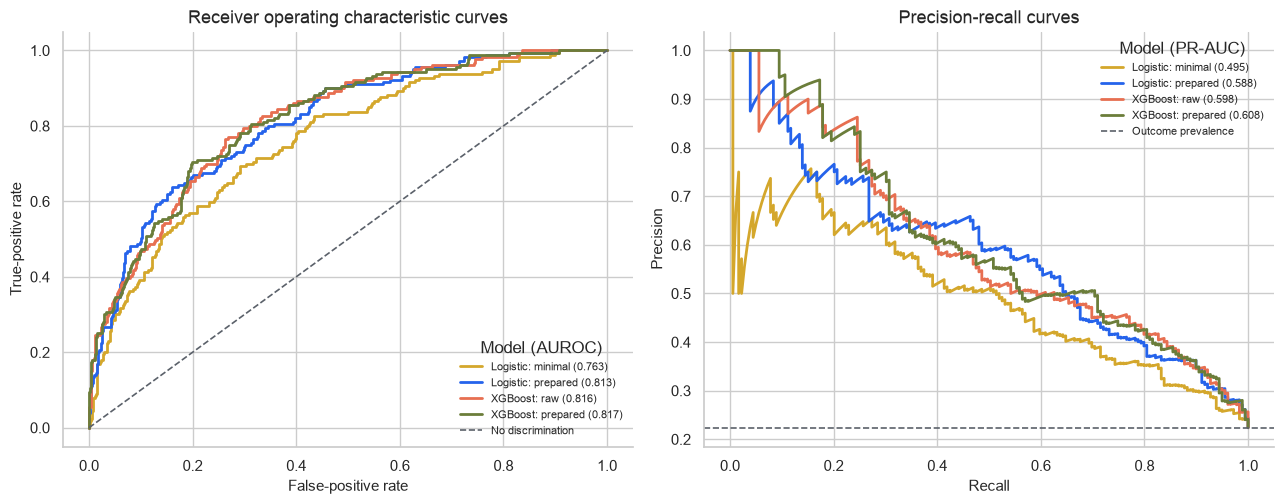

In [98]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

for model_name, probability in test_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, probability)
    axes[0].plot(
        fpr,
        tpr,
        label=f"{model_name} ({evaluation.loc[model_name, 'AUROC']:.3f})",
        color=MODEL_COLORS[model_name],
        linewidth=2,
    )
axes[0].plot([0, 1], [0, 1], linestyle="--", color="#5B616A", linewidth=1.2, label="No discrimination")
axes[0].set_title("Receiver operating characteristic curves")
axes[0].set_xlabel("False-positive rate")
axes[0].set_ylabel("True-positive rate")
axes[0].legend(title="Model (AUROC)", fontsize=8)

for model_name, probability in test_probabilities.items():
    precision, recall, _ = precision_recall_curve(y_test, probability)
    axes[1].plot(
        recall,
        precision,
        label=f"{model_name} ({evaluation.loc[model_name, 'PR-AUC']:.3f})",
        color=MODEL_COLORS[model_name],
        linewidth=2,
    )
axes[1].axhline(y_test.mean(), linestyle="--", color="#5B616A", linewidth=1.2, label="Outcome prevalence")
axes[1].set_title("Precision-recall curves")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(title="Model (PR-AUC)", fontsize=8)

plt.tight_layout()
plt.show()

AUROC measures ranking across thresholds. PR-AUC emphasizes performance on the hospitalized class and should be interpreted relative to the observed outcome prevalence shown by the dashed line.

### Compare probability calibration

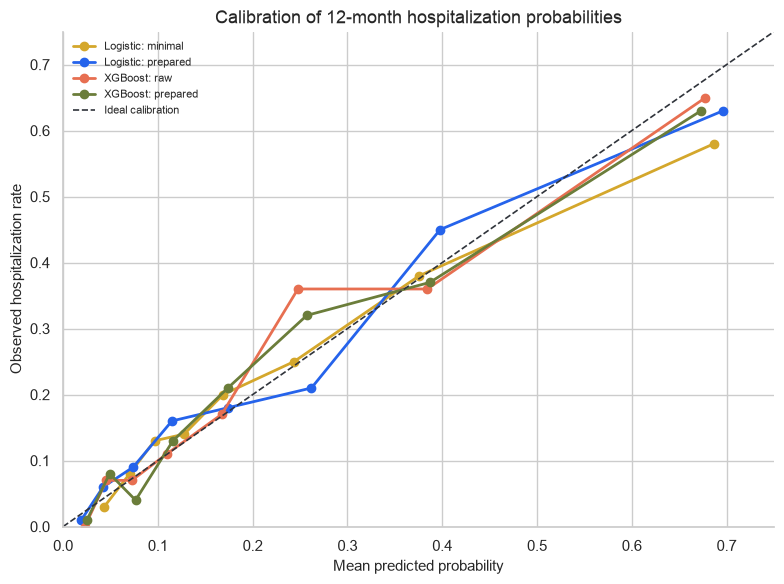

In [99]:
fig, ax = plt.subplots(figsize=(8, 6))
for model_name, probability in test_probabilities.items():
    observed, predicted = calibration_curve(y_test, probability, n_bins=8, strategy="quantile")
    ax.plot(
        predicted,
        observed,
        marker="o",
        linewidth=2,
        label=model_name,
        color=MODEL_COLORS[model_name],
    )
ax.plot([0, 1], [0, 1], linestyle="--", color="#30343B", linewidth=1.2, label="Ideal calibration")
ax.set_title("Calibration of 12-month hospitalization probabilities")
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed hospitalization rate")
ax.set_xlim(0, 0.75)
ax.set_ylim(0, 0.75)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Calibration curves compare predicted probabilities with observed hospitalization rates. Even a model with good discrimination may require calibration before clinical risk communication.

### Compare threshold-based performance

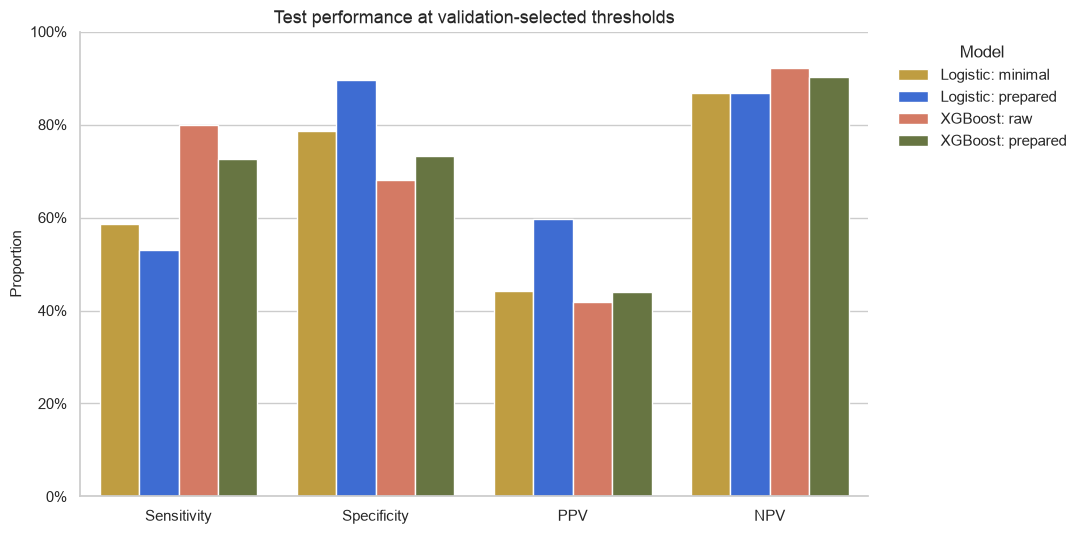

In [100]:
threshold_metrics = evaluation[["Sensitivity", "Specificity", "PPV", "NPV"]]
plot_data = threshold_metrics.reset_index().melt(id_vars="Model", var_name="Metric", value_name="Value")

fig, ax = plt.subplots(figsize=(11, 5.5))
sns.barplot(
    data=plot_data,
    x="Metric",
    y="Value",
    hue="Model",
    palette=MODEL_COLORS,
    ax=ax,
)
ax.set_title("Test performance at validation-selected thresholds")
ax.set_xlabel("")
ax.set_ylabel("Proportion")
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(lambda value, position: f"{value:.0%}")
ax.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## Step 9: Inspect model interpretation

### SHAP interpretation of prepared XGBoost

SHAP values attribute each prediction to the prepared features used by the fitted XGBoost model. The analysis includes all 800 patients in the untouched test set.

In [104]:
prepared_xgb_pipeline = fitted_models["XGBoost: prepared"]
prepared_xgb_preprocessor = prepared_xgb_pipeline.named_steps["preprocess"]
prepared_xgb_model = prepared_xgb_pipeline.named_steps["model"]

prepared_feature_names = pd.Index(
    prepared_xgb_preprocessor.get_feature_names_out()
).str.replace(
    r"^(continuous|log_numeric|binary|categorical)__", "", regex=True
).str.replace(
    r"^missing_flags__missingindicator_", "missing: ", regex=True
).str.replace("_", " ", regex=False)

prepared_xgb_matrix = prepared_xgb_preprocessor.transform(Xp_test)
if hasattr(prepared_xgb_matrix, "toarray"):
    prepared_xgb_matrix = prepared_xgb_matrix.toarray()

prepared_xgb_frame = pd.DataFrame(
    prepared_xgb_matrix,
    columns=prepared_feature_names,
    index=Xp_test.index,
)
shap_test_data = prepared_xgb_frame
assert len(shap_test_data) == len(Xp_test)

shap_explainer = shap.TreeExplainer(prepared_xgb_model)
shap_values = shap_explainer(shap_test_data, check_additivity=False)
print(f"SHAP explanations generated for all {len(shap_test_data):,} test patients.")

SHAP explanations generated for all 800 test patients.


### SHAP beeswarm summary

Each point represents one patient. Horizontal position shows whether a feature increased or decreased the model output, while color shows the transformed feature value.

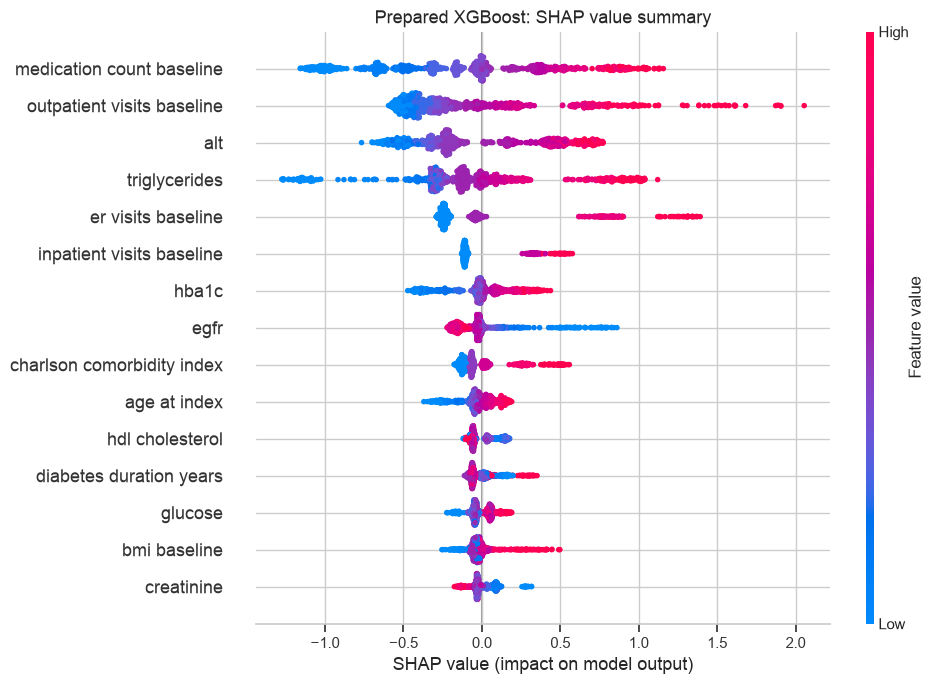

In [105]:
shap.summary_plot(
    shap_values.values,
    shap_test_data,
    plot_type="dot",
    max_display=15,
    plot_size=(10, 7),
    show=False,
)
plt.title("Prepared XGBoost: SHAP value summary")
plt.tight_layout()
plt.show()

### Mean absolute SHAP summary

Mean absolute SHAP values summarize the average magnitude of each feature's contribution across the sampled patients, regardless of direction.

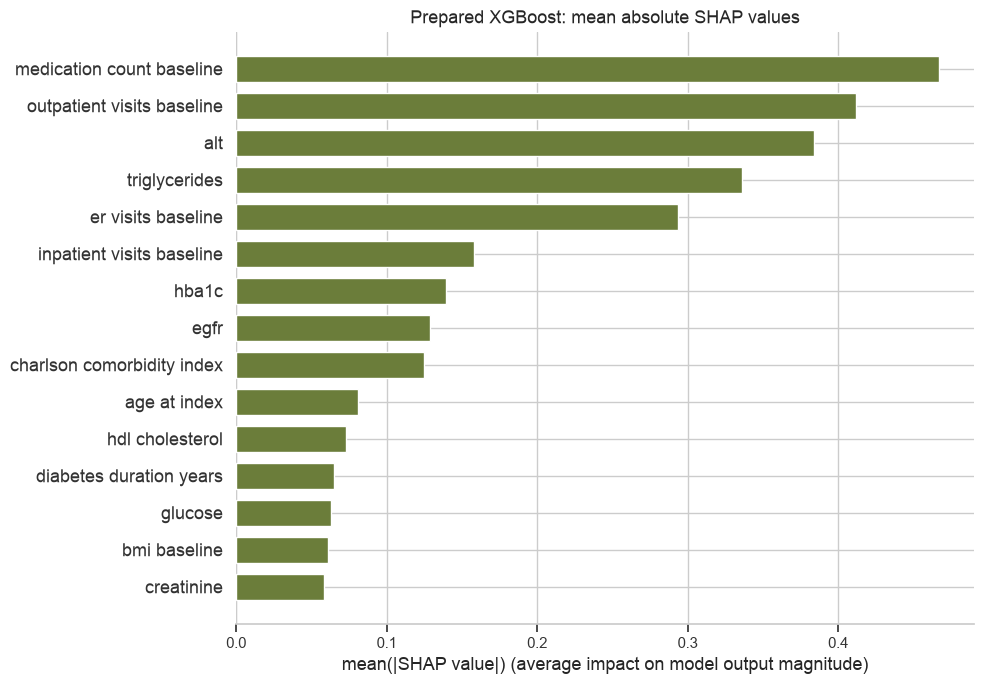

In [106]:
shap.summary_plot(
    shap_values.values,
    shap_test_data,
    plot_type="bar",
    max_display=15,
    plot_size=(10, 7),
    color=MODEL_COLORS["XGBoost: prepared"],
    show=False,
)
plt.title("Prepared XGBoost: mean absolute SHAP values")
plt.tight_layout()
plt.show()

Positive SHAP values increase the prepared XGBoost model's raw output for hospitalization; negative values decrease it. SHAP values explain the fitted model's predictions, not causal effects or clinical importance. Correlated features may share or redistribute attribution, so rankings should be interpreted cautiously.

## Observed results

In [107]:
best_auroc_model = evaluation["AUROC"].idxmax()
result_summary = pd.Series({
    "Best test AUROC model": best_auroc_model,
    "Best test AUROC": evaluation.loc[best_auroc_model, "AUROC"],
    "Raw XGBoost test AUROC": evaluation.loc["XGBoost: raw", "AUROC"],
    "Prepared logistic test AUROC": evaluation.loc["Logistic: prepared", "AUROC"],
}).to_frame("value")
display(result_summary)

,value
Best test AUROC model,XGBoost: prepared
Best test AUROC,0.817343
Raw XGBoost test AUROC,0.815642
Prepared logistic test AUROC,0.812782


## Takeaways and next steps

- Preprocessing does not automatically improve AUROC. It helps when it makes a model's representation better match the data-generating relationship, as the log transformations do in this synthetic example.
- Logistic regression still needs explicit handling of missing values and categorical variables. Scaling also stabilizes regularized estimation when predictors use very different units.
- Tree-based XGBoost can use raw numeric scales, nonlinear thresholds, interactions, and native numeric missing values.
- Scaling and monotonic transformations usually add little to a tree model; the prepared-XGBoost control tests this directly.
- Better discrimination does not guarantee better calibration or clinical usefulness.
- SHAP values explain fitted-model predictions but do not establish causality.

Possible extensions include bootstrap confidence intervals, explicit probability calibration, decision-curve analysis, and subgroup performance assessment.
